# Lab 3: árboles de decisión y redes neuronales

Comparamos un árbol de decisión y una red neuronal multicapa para clasificar
imágenes de dígitos manuscritos del dataset Digits. Evaluamos su rendimiento,
los efectos de la complejidad y la regularización, y la facilidad para interpretar
sus predicciones.

## 1. Configuración

Se utilizan NumPy, pandas, Matplotlib y scikit-learn del entorno del proyecto.
Las dependencias están registradas en `requirements.txt`, en la raíz del repositorio.
La semilla es 42 para las particiones y los modelos. Cada red usa un generador
independiente con esa semilla; el entrenamiento neuronal se limita a dos hilos
para reducir la variabilidad numérica entre ejecuciones.

In [1]:
import copy
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.datasets import load_digits
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
    f1_score, log_loss, precision_score, recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from threadpoolctl import threadpool_limits

SEMILLA = 42
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10})
pd.set_option("display.max_columns", 15)

## 2. Datos y exploración

Usamos `load_digits()` de scikit-learn: un subconjunto de **1,797 muestras** de
*Optical Recognition of Handwritten Digits* de UCI, no el conjunto original completo.
Cada imagen tiene **8 × 8 píxeles**, representados por 64 intensidades entre 0 y 16.
La variable objetivo, `digit`, indica una de diez clases: del 0 al 9.

Las clases tienen tamaños similares. Se revisan valores faltantes, píxeles constantes
y la distribución de clases antes de entrenar. También comparamos un árbol limitado
a un píxel con otro que utiliza las 64 entradas; el primer control ilustra la
información limitada de esa posición, sin descartar por sí solo todos los demás píxeles.

Fuentes: [Digits en scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html)
y [dataset original en UCI](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits).

Dimensiones de X: (1797, 64)
Rango de intensidades: 0.0 a 16.0
Valores faltantes: 0
Columnas constantes: ['pixel_0_0', 'pixel_4_0', 'pixel_4_7']


,muestras,porcentaje
digit,,
0,178,9.91
1,182,10.13
2,177,9.85
3,183,10.18
4,181,10.07
5,182,10.13
6,181,10.07
7,179,9.96
8,174,9.68


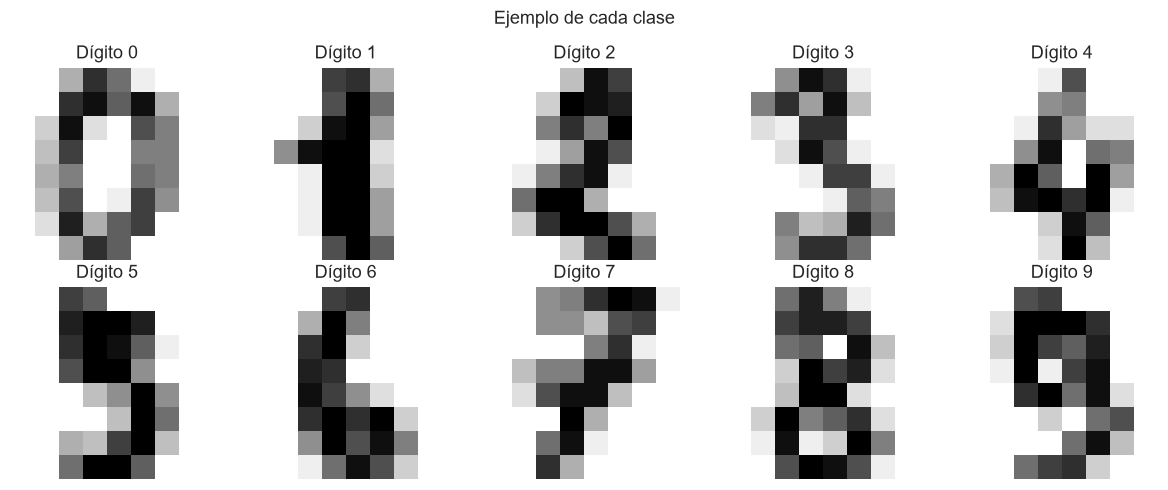

In [2]:
datos = load_digits()
NOMBRES_VARIABLES = [f"pixel_{fila}_{col}" for fila in range(8) for col in range(8)]
X = pd.DataFrame(datos.data, columns=NOMBRES_VARIABLES)
y = pd.Series(datos.target, name="digit")
CLASES = np.asarray(datos.target_names)
NOMBRES_CLASES = [str(c) for c in CLASES]

print("Dimensiones de X:", X.shape)
print("Rango de intensidades:", X.to_numpy().min(), "a", X.to_numpy().max())
print("Valores faltantes:", int(X.isna().sum().sum()))
print("Columnas constantes:", X.columns[X.nunique() == 1].tolist())
assert not X.isna().any().any()
assert X.shape == (1797, 64) and y.nunique() == 10

distribucion = y.value_counts().sort_index().rename("muestras").to_frame()
distribucion["porcentaje"] = 100 * distribucion["muestras"] / len(y)
display(distribucion.round(2))

fig, axes = plt.subplots(2, 5, figsize=(11, 4.5))
for clase, ax in zip(CLASES, axes.flat):
    ejemplo = np.flatnonzero(y.to_numpy() == clase)[0]
    ax.imshow(datos.images[ejemplo], cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"Dígito {clase}")
    ax.axis("off")
plt.suptitle("Ejemplo de cada clase")
plt.tight_layout()
plt.show()

## 3. Particiones y preprocesamiento

Reservamos el 20% para prueba y dividimos el resto en entrenamiento y validación,
con proporciones finales aproximadas de **64% / 16% / 20%**. Las dos divisiones son
estratificadas y sus índices se comparten entre todos los modelos.

El árbol utiliza las intensidades originales porque aprende umbrales por píxel.
Para la red, `StandardScaler` centra y escala las entradas para facilitar la
optimización; se ajusta únicamente con entrenamiento y después transforma validación
y prueba. No hace falta imputar ni codificar variables. Conservamos los píxeles
constantes para mantener las 64 posiciones de la imagen.

Entrenamiento ajusta reglas y pesos. Validación elige la profundidad del árbol,
la regularización de la red y la época que se restaura. Prueba se evalúa al final,
sin utilizar sus resultados para modificar los modelos ni reajustarlos con validación.

,partición,muestras,porcentaje
0,Entrenamiento,1149,63.94
1,Validación,288,16.03
2,Prueba,360,20.03


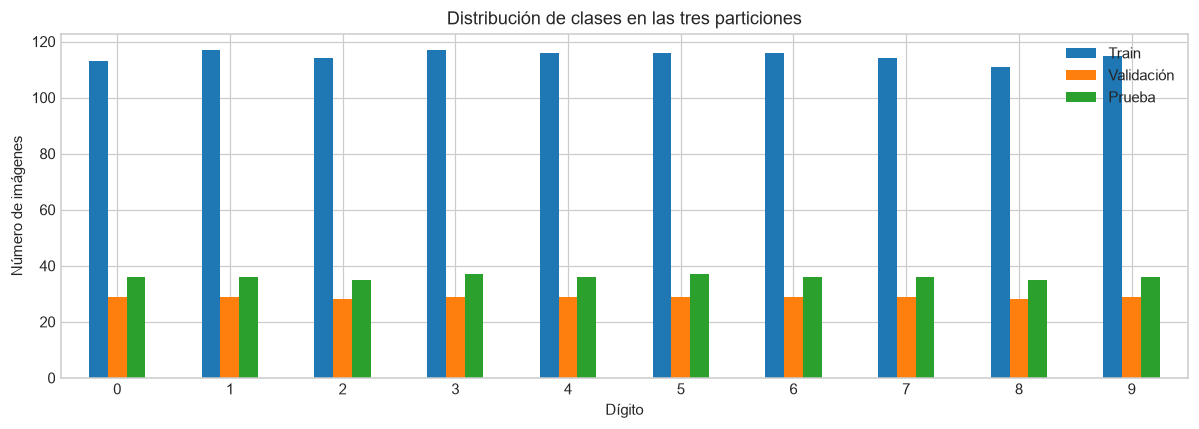

Baseline de clase mayoritaria, accuracy de validación: 0.1007
Árbol con un solo píxel, accuracy de validación: 0.2431


In [3]:
indices = np.arange(len(X))
idx_desarrollo, idx_test = train_test_split(
    indices, test_size=0.20, stratify=y, random_state=SEMILLA,
)
idx_train, idx_val = train_test_split(
    idx_desarrollo, test_size=0.20, stratify=y.iloc[idx_desarrollo], random_state=SEMILLA,
)
assert not (set(idx_train) & set(idx_val) or set(idx_train) & set(idx_test)
            or set(idx_val) & set(idx_test))
assert len(idx_train) + len(idx_val) + len(idx_test) == len(X)

X_train, X_val, X_test = X.iloc[idx_train], X.iloc[idx_val], X.iloc[idx_test]
y_train, y_val, y_test = y.iloc[idx_train], y.iloc[idx_val], y.iloc[idx_test]

scaler = StandardScaler()
X_train_nn = scaler.fit_transform(X_train)
X_val_nn = scaler.transform(X_val)
X_test_nn = scaler.transform(X_test)
assert np.allclose(scaler.mean_, X_train.mean().to_numpy())

particiones = pd.DataFrame({
    "partición": ["Entrenamiento", "Validación", "Prueba"],
    "muestras": [len(idx_train), len(idx_val), len(idx_test)],
})
particiones["porcentaje"] = 100 * particiones["muestras"] / len(X)
display(particiones.round(2))

conteos = pd.DataFrame({
    "Train": y_train.value_counts(), "Validación": y_val.value_counts(),
    "Prueba": y_test.value_counts(),
}).sort_index()
conteos.plot.bar(figsize=(11, 4), rot=0)
plt.title("Distribución de clases en las tres particiones")
plt.xlabel("Dígito")
plt.ylabel("Número de imágenes")
plt.tight_layout()
plt.show()

baseline_mayoria = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pixel_unico = ["pixel_3_3"]  # Posición fijada antes de observar los resultados.
baseline_pixel = DecisionTreeClassifier(max_depth=3, random_state=SEMILLA)
baseline_pixel.fit(X_train[pixel_unico], y_train)
print(f"Baseline de clase mayoritaria, accuracy de validación: {baseline_mayoria.score(X_val, y_val):.4f}")
print(f"Árbol con un solo píxel, accuracy de validación: {baseline_pixel.score(X_val[pixel_unico], y_val):.4f}")


## 4. Árbol de decisión y complejidad

Se comparan profundidades máximas de 2, 4, 6, 8, 12 y sin límite, manteniendo
`min_samples_leaf=2` y la misma semilla. Seleccionamos el mayor **F1 macro de validación**;
en caso de empate, preferimos menos hojas. El promedio macro da el mismo peso a
cada dígito. La curva de accuracy permite observar cómo cambia el ajuste al aumentar
la profundidad.

,Max depth,Profundidad real,Hojas,Nodos,Train Accuracy,Val Accuracy,Val F1 macro,Tiempo fit (s)
0,2,2,4,7,0.3229,0.3194,0.2070,0.0037
1,4,4,13,25,0.5883,0.5590,0.5120,0.0054
2,6,6,36,71,0.8216,0.7604,0.7587,0.0079
3,8,8,61,121,0.9217,0.8021,0.8018,0.0086
4,12,12,94,187,0.9695,0.8264,0.8250,0.0096
5,Sin límite,12,94,187,0.9695,0.8264,0.8250,0.0095


Profundidad elegida por validación: 12


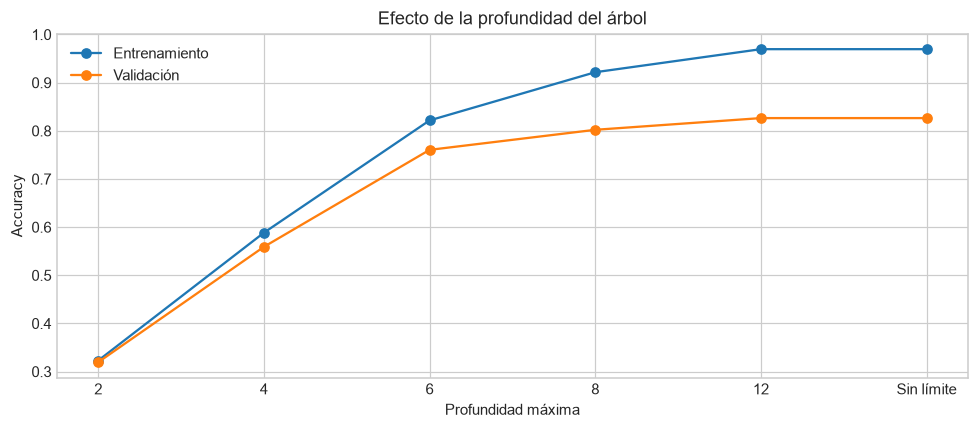

In [4]:
profundidades = [2, 4, 6, 8, 12, None]
arboles = {}
filas_arbol = []
for profundidad in profundidades:
    etiqueta = str(profundidad) if profundidad is not None else "Sin límite"
    candidato = DecisionTreeClassifier(
        max_depth=profundidad, min_samples_leaf=2, random_state=SEMILLA,
    )
    inicio = perf_counter()
    candidato.fit(X_train, y_train)
    segundos = perf_counter() - inicio
    pred_train = candidato.predict(X_train)
    pred_val = candidato.predict(X_val)
    arboles[etiqueta] = candidato
    filas_arbol.append({
        "Max depth": etiqueta, "Profundidad real": candidato.get_depth(),
        "Hojas": candidato.get_n_leaves(), "Nodos": candidato.tree_.node_count,
        "Train Accuracy": accuracy_score(y_train, pred_train),
        "Val Accuracy": accuracy_score(y_val, pred_val),
        "Val F1 macro": f1_score(y_val, pred_val, average="macro", zero_division=0),
        "Tiempo fit (s)": segundos,
    })

tabla_arboles = pd.DataFrame(filas_arbol)
display(tabla_arboles.round(4))
seleccion_arbol = tabla_arboles.sort_values(
    ["Val F1 macro", "Hojas"], ascending=[False, True], kind="stable",
).iloc[0]
arbol_final = arboles[seleccion_arbol["Max depth"]]
print("Profundidad elegida por validación:", seleccion_arbol["Max depth"])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tabla_arboles["Max depth"], tabla_arboles["Train Accuracy"], "o-", label="Entrenamiento")
ax.plot(tabla_arboles["Max depth"], tabla_arboles["Val Accuracy"], "o-", label="Validación")
ax.set(title="Efecto de la profundidad del árbol", xlabel="Profundidad máxima", ylabel="Accuracy")
ax.legend()
plt.tight_layout()
plt.show()


## 5. Red neuronal

La red `MLPClassifier` tiene arquitectura **64–64–32–10**: 64 entradas, dos capas
ocultas de 64 y 32 neuronas con ReLU y una salida de diez neuronas con softmax.
Sus **6,570 parámetros**, incluidos los sesgos, permiten combinar intensidades de
distintos píxeles mediante dos transformaciones no lineales, con un tamaño moderado
para este dataset. ReLU aplica `max(0, z)` y softmax produce probabilidades por clase.

Se entrena con entropía cruzada, **Adam**, tasa inicial **0.001** y minibatches de
**64** imágenes. La regularización L2 empieza en `alpha=0.0001`. El presupuesto es
**250 épocas**, con paciencia de **20** y mejora mínima de validación de **0.0001**.

Cada llamada a `partial_fit` recorre una época y conserva el estado de Adam.
Guardamos la red con menor pérdida absoluta de validación y la restauramos al
terminar. La paciencia se reinicia cuando la mejora acumulada desde su referencia
supera 0.0001; puede detener el entrenamiento antes del límite. Se usa nuestra
validación explícita, sin crear otra partición interna.

Las curvas muestran la entropía cruzada predictiva de entrenamiento y validación,
sin sumar L2, aunque el objetivo de entrenamiento sí incluye esa penalización.

Referencia: [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html).

In [5]:
ARQUITECTURA = (64, 32)
MAX_EPOCAS = 250
PACIENCIA = 20
MEJORA_MINIMA = 1e-4

def entrenar_red(alpha):
    red = MLPClassifier(
        hidden_layer_sizes=ARQUITECTURA, activation="relu", solver="adam",
        alpha=alpha, batch_size=64, learning_rate_init=0.001,
        random_state=np.random.RandomState(SEMILLA), shuffle=True,
        early_stopping=False,
    )
    historial = []
    mejor_perdida = np.inf
    referencia_paciencia = np.inf
    mejor_red = None
    mejor_epoca = 0
    sin_mejora = 0
    inicio = perf_counter()

    with threadpool_limits(limits=2):
        for epoca in range(1, MAX_EPOCAS + 1):
            red.partial_fit(X_train_nn, y_train, classes=CLASES)
            proba_train = red.predict_proba(X_train_nn)
            proba_val = red.predict_proba(X_val_nn)
            perdida_train = log_loss(y_train, proba_train, labels=CLASES)
            perdida_val = log_loss(y_val, proba_val, labels=CLASES)
            historial.append({
                "epoch": epoca, "train_loss": perdida_train, "val_loss": perdida_val,
                "train_accuracy": accuracy_score(y_train, red.classes_[proba_train.argmax(axis=1)]),
                "val_accuracy": accuracy_score(y_val, red.classes_[proba_val.argmax(axis=1)]),
            })

            # Guardar el mínimo absoluto para restaurar sus pesos.
            if perdida_val < mejor_perdida:
                mejor_perdida = perdida_val
                mejor_red = copy.deepcopy(red)
                mejor_epoca = epoca
            # Una mejora suficiente reinicia la paciencia, sin cambiar el criterio de guardado.
            if perdida_val < referencia_paciencia - MEJORA_MINIMA:
                referencia_paciencia = perdida_val
                sin_mejora = 0
            else:
                sin_mejora += 1
            if sin_mejora >= PACIENCIA:
                break

    segundos = perf_counter() - inicio
    historial = pd.DataFrame(historial)
    assert mejor_red is not None and np.isfinite(historial[["train_loss", "val_loss"]]).all().all()
    assert np.isclose(
        log_loss(y_val, mejor_red.predict_proba(X_val_nn), labels=CLASES),
        mejor_perdida, atol=1e-12,
    )
    return {
        "modelo": mejor_red, "historial": historial, "alpha": alpha,
        "mejor_epoca": mejor_epoca, "epocas_ejecutadas": len(historial),
        "mejor_val_loss": mejor_perdida, "segundos": segundos,
        "motivo_parada": "paciencia" if sin_mejora >= PACIENCIA else "presupuesto de épocas",
        "parametros": sum(w.size for w in mejor_red.coefs_) + sum(b.size for b in mejor_red.intercepts_),
    }

def graficar_aprendizaje(resultado, titulo):
    historial = resultado["historial"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for columna, etiqueta in (("train_loss", "Entrenamiento"), ("val_loss", "Validación")):
        axes[0].plot(historial["epoch"], historial[columna], label=etiqueta)
    for columna, etiqueta in (("train_accuracy", "Entrenamiento"), ("val_accuracy", "Validación")):
        axes[1].plot(historial["epoch"], historial[columna], label=etiqueta)
    for ax in axes:
        ax.axvline(resultado["mejor_epoca"], color="black", linestyle="--", alpha=0.5,
                   label=f"Modelo restaurado: época {resultado['mejor_epoca']}")
        if resultado["mejor_epoca"] != resultado["epocas_ejecutadas"]:
            ax.axvline(resultado["epocas_ejecutadas"], color="gray", linestyle=":",
                       label=f"Fin: época {resultado['epocas_ejecutadas']}")
        ax.set_xlabel("Época")
        ax.legend(fontsize=8)
    axes[0].set(title="Entropía cruzada", ylabel="Pérdida")
    axes[1].set(title="Accuracy", ylabel="Proporción de aciertos")
    fig.suptitle(f"{titulo} | Fin por {resultado['motivo_parada']}")
    plt.tight_layout()
    plt.show()

Arquitectura: 64–64–32–10 | Parámetros: 6,570
Épocas ejecutadas: 60 | Restaurada: 40 | Fin por paciencia
Menor pérdida de validación: 0.1773


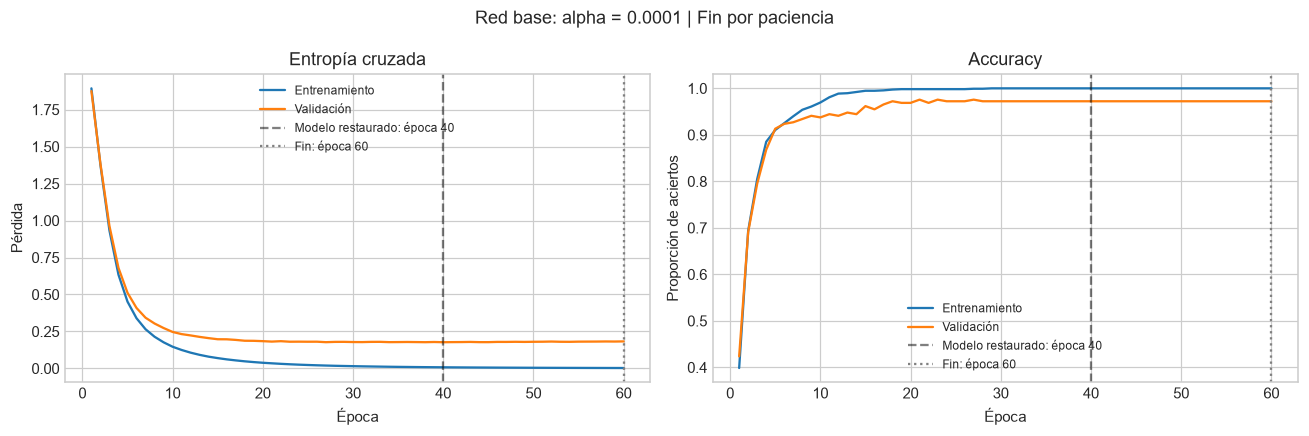

In [6]:
red_base = entrenar_red(alpha=1e-4)
print(f"Arquitectura: 64–64–32–10 | Parámetros: {red_base['parametros']:,}")
print(f"Épocas ejecutadas: {red_base['epocas_ejecutadas']} | "
      f"Restaurada: {red_base['mejor_epoca']} | Fin por {red_base['motivo_parada']}")
print(f"Menor pérdida de validación: {red_base['mejor_val_loss']:.4f}")
graficar_aprendizaje(red_base, "Red base: alpha = 0.0001")

## 6. Experimento adicional: regularización L2

Aumentamos `alpha` de **0.0001 a 0.01**, manteniendo arquitectura, inicialización,
particiones, escalado, Adam, minibatch y regla de parada. Elegimos la red final por
su menor pérdida de validación. La duración efectiva puede cambiar con esa regla,
por lo que también comparamos las pérdidas a igual número de épocas.

,Experimento,Alpha,Épocas ejecutadas,Mejor época,Motivo de fin,Val Loss,Val Accuracy
0,Base (L2=0.0001),0.0001,60,40,paciencia,0.1773,0.9722
1,L2 mayor (L2=0.01),0.0100,250,250,presupuesto de épocas,0.0582,0.9861


Red elegida únicamente por validación: L2 mayor (L2=0.01)


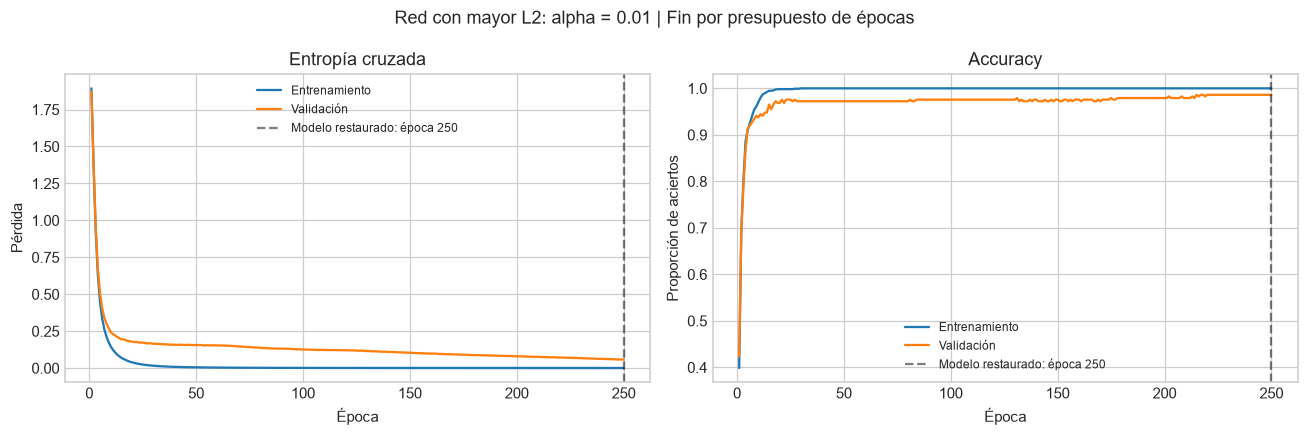

In [7]:
red_regularizada = entrenar_red(alpha=1e-2)
experimentos_red = {"Base (L2=0.0001)": red_base, "L2 mayor (L2=0.01)": red_regularizada}

tabla_validacion_red = pd.DataFrame([
    {"Experimento": nombre, "Alpha": r["alpha"],
     "Épocas ejecutadas": r["epocas_ejecutadas"], "Mejor época": r["mejor_epoca"],
     "Motivo de fin": r["motivo_parada"],
     "Val Loss": r["mejor_val_loss"],
     "Val Accuracy": r["modelo"].score(X_val_nn, y_val)}
    for nombre, r in experimentos_red.items()
])
display(tabla_validacion_red.round(4))
nombre_red_final = min(experimentos_red, key=lambda nombre: experimentos_red[nombre]["mejor_val_loss"])
resultado_red_final = experimentos_red[nombre_red_final]
red_final = resultado_red_final["modelo"]
print("Red elegida únicamente por validación:", nombre_red_final)
graficar_aprendizaje(red_regularizada, "Red con mayor L2: alpha = 0.01")

### Comparación a igual duración

Comparamos la última época disponible en ambos historiales, antes de restaurar
los mejores modelos. Así, las redes han procesado el mismo número de minibatches
con inicialización y secuencia aleatoria comparables. Este control usa únicamente
entrenamiento y validación; sus métricas corresponden a esa época, no a los modelos finales.

In [8]:
EPOCA_COMUN = min(r["epocas_ejecutadas"] for r in experimentos_red.values())
filas_control = []
for nombre, resultado in experimentos_red.items():
    fila = resultado["historial"].set_index("epoch").loc[EPOCA_COMUN]
    filas_control.append({
        "Experimento": nombre, "Época común": EPOCA_COMUN,
        "Train Loss": fila["train_loss"], "Val Loss": fila["val_loss"],
        "Train Accuracy": fila["train_accuracy"], "Val Accuracy": fila["val_accuracy"],
    })
tabla_control_l2 = pd.DataFrame(filas_control)
display(tabla_control_l2.round(4))

delta_control_val = tabla_control_l2.iloc[1]["Val Loss"] - tabla_control_l2.iloc[0]["Val Loss"]
display(Markdown(
    f"En la época **{EPOCA_COMUN}**, la diferencia de pérdida de validación "
    f"(L2 mayor − base) es **{delta_control_val:+.4f}**. "
))

,Experimento,Época común,Train Loss,Val Loss,Train Accuracy,Val Accuracy
0,Base (L2=0.0001),60,0.0030,0.1829,1.0,0.9722
1,L2 mayor (L2=0.01),60,0.0036,0.1538,1.0,0.9722


En la época **60**, la diferencia de pérdida de validación (L2 mayor − base) es **-0.0291**. 

## 7. Evaluación final

Con los modelos ya seleccionados por validación, calculamos las métricas de prueba.
`Train Score` es la accuracy de entrenamiento; las demás columnas corresponden a
prueba. Precision, recall y F1 usan **promedio macro** sobre las diez clases,
con `zero_division=0` si alguna clase no recibe predicciones.

In [9]:
def evaluar_modelo(nombre, modelo, entradas_train, entradas_test):
    pred_train = modelo.predict(entradas_train)
    pred_test = modelo.predict(entradas_test)
    train_score = accuracy_score(y_train, pred_train)
    test_score = accuracy_score(y_test, pred_test)
    fila = {
        "Model": nombre, "Train Score": train_score, "Accuracy": test_score,
        "Precision": precision_score(y_test, pred_test, labels=CLASES, average="macro", zero_division=0),
        "Recall": recall_score(y_test, pred_test, labels=CLASES, average="macro", zero_division=0),
        "F1-score": f1_score(y_test, pred_test, labels=CLASES, average="macro", zero_division=0),
        "Gap train-test": train_score - test_score,
    }
    return fila, pred_test

fila_arbol, pred_test_arbol = evaluar_modelo("Decision Tree", arbol_final, X_train, X_test)
fila_red, pred_test_red = evaluar_modelo("Neural Network", red_final, X_train_nn, X_test_nn)
COLUMNAS_PDF = ["Train Score", "Accuracy", "Precision", "Recall", "F1-score"]
comparacion = pd.DataFrame([fila_arbol, fila_red]).set_index("Model")[COLUMNAS_PDF]
display(comparacion.round(4))

,Train Score,Accuracy,Precision,Recall,F1-score
Model,,,,,
Decision Tree,0.9695,0.8167,0.8190,0.8158,0.8144
Neural Network,1.0000,0.9778,0.9784,0.9775,0.9776


## 8. Matrices de confusión y errores

Las filas indican la clase real y las columnas, la predicha. La diagonal contiene
los aciertos. Ambas matrices muestran conteos sobre las mismas imágenes de prueba,
con el mismo orden de clases y escala de color.

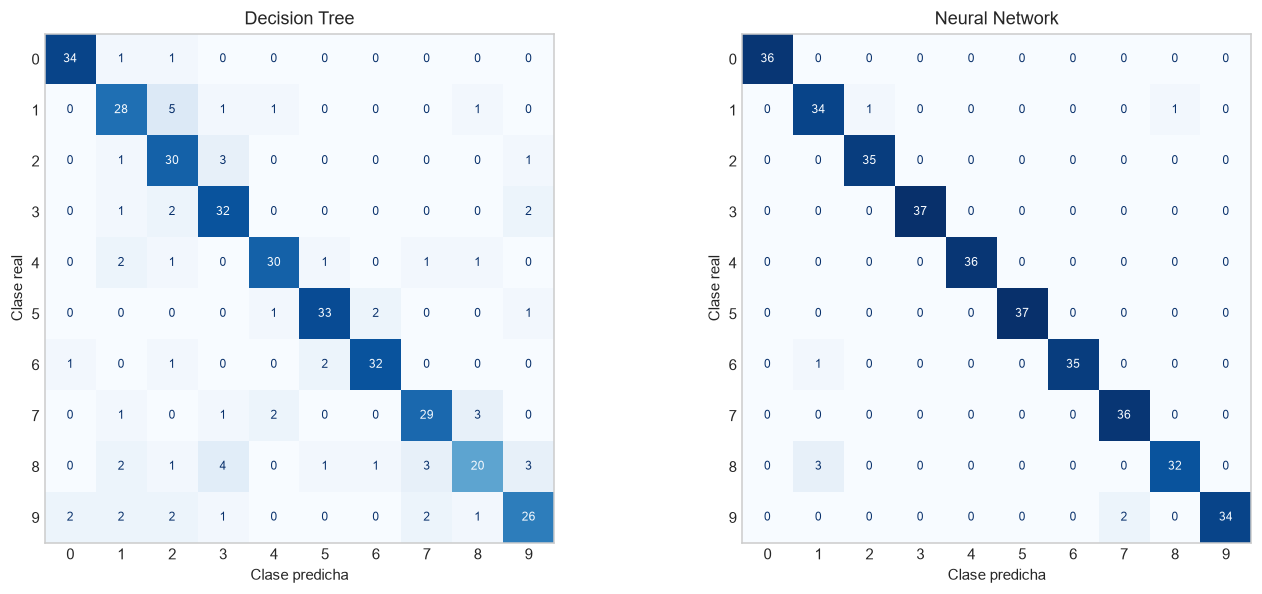

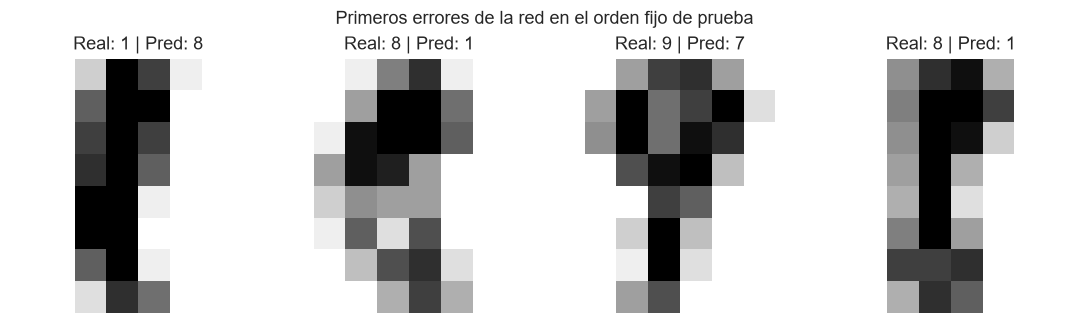

**Decision Tree:** acertó 20 de 35 imágenes del dígito 8. Confusiones más frecuentes (real → predicha): 1 → 2 (5 casos); 8 → 3 (4 casos).

**Neural Network:** acertó 32 de 35 imágenes del dígito 8. Confusiones más frecuentes (real → predicha): 8 → 1 (3 casos); 9 → 7 (2 casos).

In [10]:
matrices = {
    "Decision Tree": confusion_matrix(y_test, pred_test_arbol, labels=CLASES),
    "Neural Network": confusion_matrix(y_test, pred_test_red, labels=CLASES),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, nombre, predicciones in (
    (axes[0], "Decision Tree", pred_test_arbol),
    (axes[1], "Neural Network", pred_test_red),
):
    matriz = matrices[nombre]
    assert matriz.sum() == len(y_test)
    ConfusionMatrixDisplay(matriz, display_labels=CLASES).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d",
        im_kw={"vmin": 0, "vmax": int(y_test.value_counts().max())},
        text_kw={"fontsize": 8},
    )
    ax.set_title(nombre)
    ax.grid(False)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
plt.tight_layout()
plt.show()

errores = np.flatnonzero(y_test.to_numpy() != pred_test_red)
if len(errores):
    fig, axes = plt.subplots(1, min(4, len(errores)), figsize=(10, 3), squeeze=False)
    for ax, posicion in zip(axes.flat, errores[:4]):
        ax.imshow(X_test.iloc[posicion].to_numpy().reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
        ax.set_title(f"Real: {y_test.iloc[posicion]} | Pred: {pred_test_red[posicion]}")
        ax.axis("off")
    fig.suptitle("Primeros errores de la red en el orden fijo de prueba")
    plt.tight_layout()
    plt.show()
else:
    print("No se observaron errores de la red en esta partición de prueba.")


resumen_errores = []
indice_8 = np.flatnonzero(CLASES == 8)[0]
for nombre, matriz in matrices.items():
    fuera_diagonal = matriz.copy()
    np.fill_diagonal(fuera_diagonal, 0)
    frecuentes = np.argsort(-fuera_diagonal, axis=None, kind="stable")[:2]
    confusiones = []
    for posicion in frecuentes:
        real, predicha = np.unravel_index(posicion, matriz.shape)
        if fuera_diagonal[real, predicha] > 0:
            confusiones.append(
                f"{CLASES[real]} → {CLASES[predicha]} ({matriz[real, predicha]} casos)"
            )
    detalle = "; ".join(confusiones) if confusiones else "ninguna"
    resumen_errores.append(
        f"**{nombre}:** acertó {matriz[indice_8, indice_8]} de "
        f"{matriz[indice_8].sum()} imágenes del dígito 8. "
        f"Confusiones más frecuentes (real → predicha): {detalle}."
    )
display(Markdown("\n\n".join(resumen_errores)))

## 9. Efecto de la regularización

Comparamos las dos variantes después de restaurar sus mejores épocas de validación.
La evaluación de prueba describe sus resultados; la elección de la red final se
mantiene según la validación.

In [11]:
filas_exploracion = []
for nombre, resultado in experimentos_red.items():
    fila, _ = evaluar_modelo(nombre, resultado["modelo"], X_train_nn, X_test_nn)
    fila.update({"Val Accuracy": resultado["modelo"].score(X_val_nn, y_val),
                 "Val Loss": resultado["mejor_val_loss"]})
    filas_exploracion.append(fila)
comparacion_l2 = pd.DataFrame(filas_exploracion).set_index("Model")
display(comparacion_l2[["Train Score", "Val Accuracy", "Val Loss", "Accuracy", "F1-score"]].round(4))

base = comparacion_l2.loc["Base (L2=0.0001)"]
regularizada = comparacion_l2.loc["L2 mayor (L2=0.01)"]
delta_test = regularizada["Accuracy"] - base["Accuracy"]

display(Markdown(
    f"La red base ejecutó **{red_base['epocas_ejecutadas']} épocas** y restauró la "
    f"**{red_base['mejor_epoca']}**; terminó por {red_base['motivo_parada']}. "
    f"La variante con mayor L2 ejecutó **{red_regularizada['epocas_ejecutadas']}** y restauró "
    f"la **{red_regularizada['mejor_epoca']}**; terminó por {red_regularizada['motivo_parada']}. "
    "Alcanzar el límite de épocas no demuestra convergencia. "
    f"La accuracy de entrenamiento fue {base['Train Score']:.4f} en la base y "
    f"{regularizada['Train Score']:.4f} con mayor L2; la pérdida de validación pasó de "
    f"{base['Val Loss']:.4f} a {regularizada['Val Loss']:.4f}. "
    f"El cambio de accuracy de prueba fue **{delta_test * 100:+.2f} puntos porcentuales**, "
    "pero combina L2 y distinta duración del entrenamiento. "
    f"A igual duración ({EPOCA_COMUN} épocas), la diferencia de pérdida de validación "
    f"fue **{delta_control_val:+.4f}**, con L2 mayor menos base."
))

,Train Score,Val Accuracy,Val Loss,Accuracy,F1-score
Model,,,,,
Base (L2=0.0001),1.0,0.9722,0.1773,0.9611,0.9609
L2 mayor (L2=0.01),1.0,0.9861,0.0582,0.9778,0.9776


La red base ejecutó **60 épocas** y restauró la **40**; terminó por paciencia. La variante con mayor L2 ejecutó **250** y restauró la **250**; terminó por presupuesto de épocas. Alcanzar el límite de épocas no demuestra convergencia. La accuracy de entrenamiento fue 1.0000 en la base y 1.0000 con mayor L2; la pérdida de validación pasó de 0.1773 a 0.0582. El cambio de accuracy de prueba fue **+1.67 puntos porcentuales**, pero combina L2 y distinta duración del entrenamiento. A igual duración (60 épocas), la diferencia de pérdida de validación fue **-0.0291**, con L2 mayor menos base.

## 10. Interpretabilidad y complejidad

El árbol permite seguir reglas sobre intensidades de píxeles hasta una clase.
La red combina esas intensidades mediante miles de pesos, por lo que sus
predicciones son más difíciles de explicar. Aumentar la profundidad del árbol
mejora su capacidad de ajuste, pero añade reglas y dificulta leerlo completo.
En una red, añadir capas o neuronas también aumenta capacidad, costo y riesgo de sobreajuste.

El gráfico muestra solo los primeros tres niveles del árbol seleccionado.
Cada nodo indica variable y umbral cuando hay una división, clase mayoritaria y
cantidad de observaciones de entrenamiento; los puntos suspensivos indican ramas
que continúan. El mapa de importancias representa reducción de impureza, no efectos
causales, y puede repartir importancia entre píxeles correlacionados.

Profundidad real del árbol: 12
Hojas: 94
Nodos: 187
Parámetros de la red: 6570


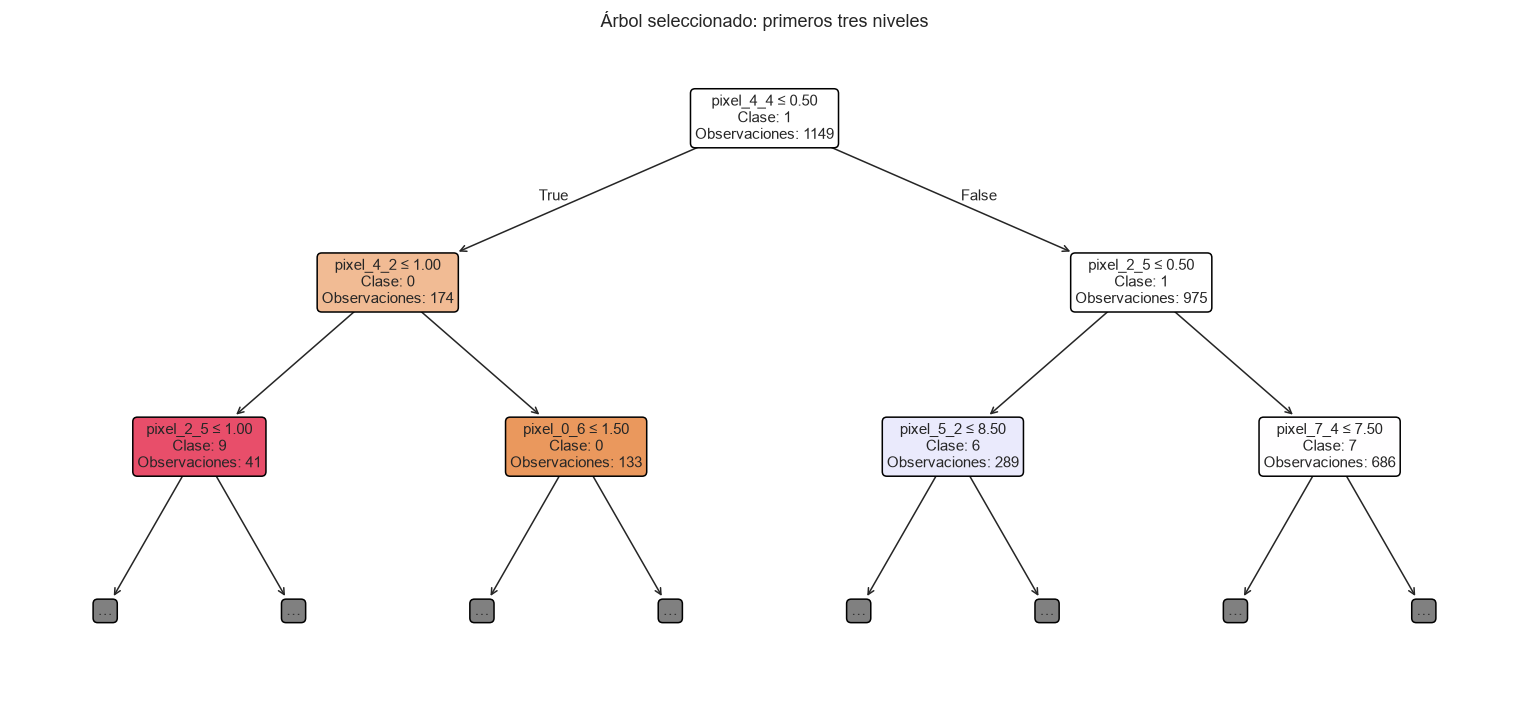

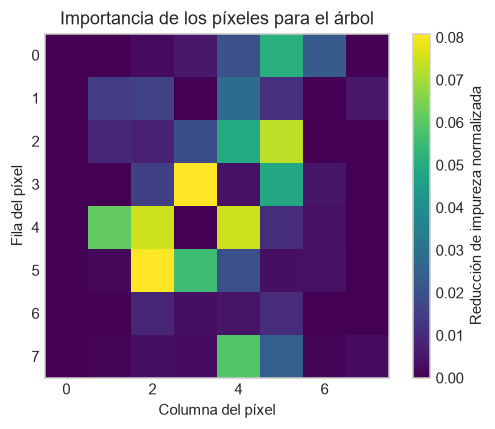


Ruta del árbol para la primera imagen de prueba:
pixel_4_4 = 0.0 <= 0.50
pixel_4_2 = 4.0 > 1.00
pixel_0_6 = 3.0 > 1.50
Clase real: 5 | Predicción: 5


In [12]:
print("Profundidad real del árbol:", arbol_final.get_depth())
print("Hojas:", arbol_final.get_n_leaves())
print("Nodos:", arbol_final.tree_.node_count)
print("Parámetros de la red:", resultado_red_final["parametros"])

fig, ax = plt.subplots(figsize=(14, 6.5))
anotaciones = plot_tree(
    arbol_final, feature_names=NOMBRES_VARIABLES, class_names=NOMBRES_CLASES,
    max_depth=2, filled=True, rounded=True, impurity=False, proportion=False,
    node_ids=True, fontsize=10, ax=ax,
)
# Sustituir los vectores de diez clases por una etiqueta breve en cada nodo.
for anotacion in anotaciones:
    texto = anotacion.get_text()
    if texto.startswith("node #"):
        nodo = int(texto.splitlines()[0].split("#")[1])
        variable = arbol_final.tree_.feature[nodo]
        clase = arbol_final.classes_[arbol_final.tree_.value[nodo].argmax()]
        division = (
            f"{NOMBRES_VARIABLES[variable]} ≤ {arbol_final.tree_.threshold[nodo]:.2f}\n"
            if variable >= 0 else ""
        )
        anotacion.set_text(
            f"{division}Clase: {clase}\nObservaciones: {arbol_final.tree_.n_node_samples[nodo]}"
        )
    elif "(...)" in texto:
        anotacion.set_text("…")
ax.set_title("Árbol seleccionado: primeros tres niveles")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
imagen_importancia = ax.imshow(arbol_final.feature_importances_.reshape(8, 8), cmap="viridis")
ax.grid(False)
ax.set(title="Importancia de los píxeles para el árbol", xlabel="Columna del píxel", ylabel="Fila del píxel")
fig.colorbar(imagen_importancia, ax=ax, label="Reducción de impureza normalizada")
plt.tight_layout()
plt.show()

# Se muestra la primera imagen de prueba, sin elegirla por su resultado.
ejemplo = X_test.iloc[[0]]
ruta = arbol_final.decision_path(ejemplo).indices
reglas = []
for nodo in ruta:
    variable = arbol_final.tree_.feature[nodo]
    if variable >= 0:
        valor = float(ejemplo.iloc[0, variable])
        umbral = float(arbol_final.tree_.threshold[nodo])
        operador = "<=" if valor <= umbral else ">"
        reglas.append(f"{NOMBRES_VARIABLES[variable]} = {valor:.1f} {operador} {umbral:.2f}")
print("\nRuta del árbol para la primera imagen de prueba:")
print("\n".join(reglas))
print("Clase real:", y_test.iloc[0], "| Predicción:", arbol_final.predict(ejemplo)[0])

## 11. Conclusiones

In [13]:
brecha_arbol = fila_arbol["Gap train-test"]
brecha_red = fila_red["Gap train-test"]
arbol_simple = tabla_arboles.iloc[0]
arbol_complejo = tabla_arboles.iloc[-1]
mejor_test = comparacion["F1-score"].idxmax()

conclusion = f'''
El mejor resultado de prueba fue el de **{mejor_test}**, con accuracy
**{comparacion.loc[mejor_test, "Accuracy"]:.4f}** y F1 macro
**{comparacion.loc[mejor_test, "F1-score"]:.4f}**. La red combinó mejor los patrones
de píxeles: en el dígito 8 acertó **{matrices["Neural Network"][indice_8, indice_8]} de
{matrices["Neural Network"][indice_8].sum()}**, frente a
**{matrices["Decision Tree"][indice_8, indice_8]}** del árbol.

El árbol de profundidad 2 subajustó, con accuracy de entrenamiento y validación
{arbol_simple["Train Accuracy"]:.4f} y {arbol_simple["Val Accuracy"]:.4f}.
El árbol sin límite mejoró el ajuste, pero alcanzó {arbol_complejo["Train Accuracy"]:.4f}
en entrenamiento frente a {arbol_complejo["Val Accuracy"]:.4f} en validación.
La brecha train–test del árbol seleccionado fue **{brecha_arbol * 100:.2f} puntos
porcentuales**, un indicio de sobreajuste más marcado que en la red
(**{brecha_red * 100:.2f} puntos**). El ajuste perfecto de la red en entrenamiento
tampoco eliminó sus errores fuera de muestra.

El árbol conserva la ventaja de explicar cada decisión mediante umbrales, aunque
sus {arbol_final.get_n_leaves()} hojas dificultan una lectura completa. La mayor
capacidad de la red fue útil para estas imágenes a cambio de menor transparencia.
Con rendimientos similares, consideraría interpretabilidad, tiempo de entrenamiento
e inferencia, memoria y costo de los errores. Aumentar L2 mejoró la pérdida de
validación incluso a igual duración en esta ejecución; la mejora final de prueba
también estuvo asociada a distintas épocas restauradas y no puede atribuirse solo a L2.
'''
display(Markdown(conclusion))


El mejor resultado de prueba fue el de **Neural Network**, con accuracy
**0.9778** y F1 macro
**0.9776**. La red combinó mejor los patrones
de píxeles: en el dígito 8 acertó **32 de
35**, frente a
**20** del árbol.

El árbol de profundidad 2 subajustó, con accuracy de entrenamiento y validación
0.3229 y 0.3194.
El árbol sin límite mejoró el ajuste, pero alcanzó 0.9695
en entrenamiento frente a 0.8264 en validación.
La brecha train–test del árbol seleccionado fue **15.29 puntos
porcentuales**, un indicio de sobreajuste más marcado que en la red
(**2.22 puntos**). El ajuste perfecto de la red en entrenamiento
tampoco eliminó sus errores fuera de muestra.

El árbol conserva la ventaja de explicar cada decisión mediante umbrales, aunque
sus 94 hojas dificultan una lectura completa. La mayor
capacidad de la red fue útil para estas imágenes a cambio de menor transparencia.
Con rendimientos similares, consideraría interpretabilidad, tiempo de entrenamiento
e inferencia, memoria y costo de los errores. Aumentar L2 mejoró la pérdida de
validación incluso a igual duración en esta ejecución; la mejora final de prueba
también estuvo asociada a distintas épocas restauradas y no puede atribuirse solo a L2.


## Referencias

- Enunciado proporcionado: `Lab3_AA_NN_EN.pdf`, *Comparing Decision Trees and Neural Networks*.
- [Digits en scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html).
- [Optical Recognition of Handwritten Digits en UCI](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits).
- [MLPClassifier y partial_fit](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html).
- [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html).
- [Precision, recall y F1](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics).